# Exploring the Data

Some ideas:
* Names:
    - Seeing consistent clients throughout time (monthly)
    - Summing over hourly and seeing change of demand per hour
* Postal code:
    - Distribution of zipcodes
    - Change in clusters throughout time (monthly/hourly)
* Numbers:
    - Change number of seniors/adults/youth/babies supported throughout time (monthly)
    - Sum of all numbers
        * Seeing that change over time as well
* Household:
    - Comparing if sum of numbers == household size
* Gender:
    - Distribution (in general and temporal- monthly/hourly)
* Overall:
    - Predicting demand (Regression - Pytorch)
    - Client clusters (KMeans)



In [39]:
##### Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

DATA_PATH = os.path.join(
    os.getcwd(),
    'Data'
)

df = pd.read_csv(
    f'{DATA_PATH}/food_clean.csv',
    parse_dates=['conversion_date']
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   first_name         912 non-null    str           
 1   last_name          910 non-null    str           
 2   postal_code        912 non-null    int64         
 3   number_of_seniors  912 non-null    int64         
 4   number_of_adults   912 non-null    int64         
 5   number_of_youth    912 non-null    int64         
 6   number_of_babies   912 non-null    int64         
 7   household_size     912 non-null    float64       
 8   gender             912 non-null    str           
 9   conversion_date    912 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(5), str(3)
memory usage: 71.4 KB


In [40]:
##### Creating month and hourly variables
df['month'] = df['conversion_date'].dt.month
df['hour'] = df['conversion_date'].dt.hour

##### Summing up individual numbers of populations
population_cols = [col for col in df.columns if col.startswith('number')]
df['number_household_sum'] = df[population_cols[0]] + \
    df[population_cols[1]] + \
    df[population_cols[2]] + \
    df[population_cols[3]]

##### Quantitative and Qualitative Variables
quant_vars = [col for col in df.columns if col.startswith('number')]
qual_vars = list(set(df.columns) - set(quant_vars))


,number_of_seniors,number_of_adults,number_of_youth,number_of_babies,number_household_sum
count,912.000000,912.000000,912.000000,912.000000,912.000000
mean,1.130482,2.086623,1.282895,0.570175,5.070175
std,1.373048,1.342605,1.374463,1.089572,3.516233
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,2.000000
50%,1.000000,2.000000,1.000000,0.000000,4.000000
75%,2.000000,3.000000,2.000000,1.000000,7.000000
max,5.000000,5.000000,5.000000,5.000000,20.000000


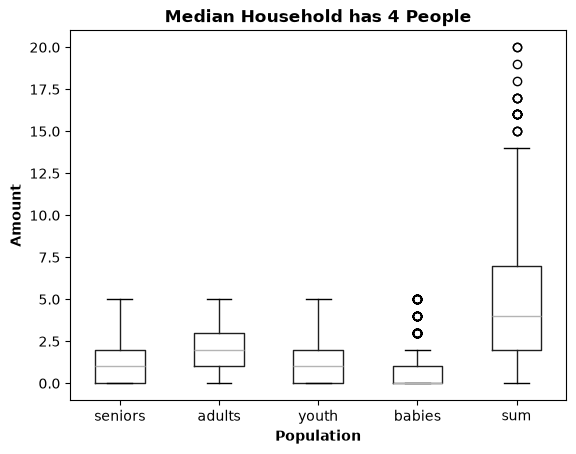

In [38]:
##### General distributions - Quant variables
### Normalizing quant_vars
# df_quant_norm = (
#     df[quant_vars] - df[quant_vars].mean()
# )/df[quant_vars].std(ddof=0)

### Statistics
display(df[quant_vars].describe())
### Box and Whisker
boxplot = df.boxplot(
    column=quant_vars, 
    grid=False,
)
## X Axis
boxplot.set_xticklabels(
    [col.split("_")[-1] for col in quant_vars]
)
boxplot.set_xlabel("Population", fontweight='bold')
## Y Axis
boxplot.set_ylabel("Amount", fontweight='bold')
## Title
boxplot.set_title('Median Household has 4 People', fontweight='bold')
plt.show()

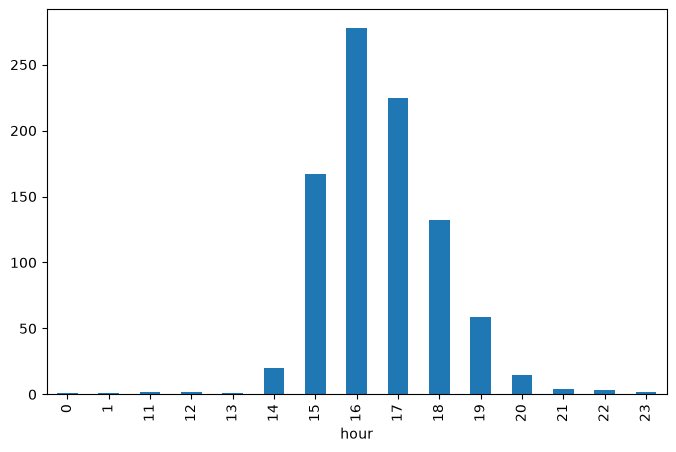

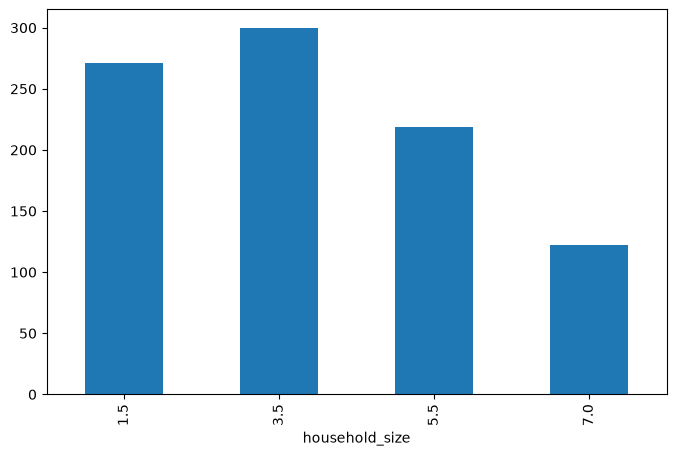

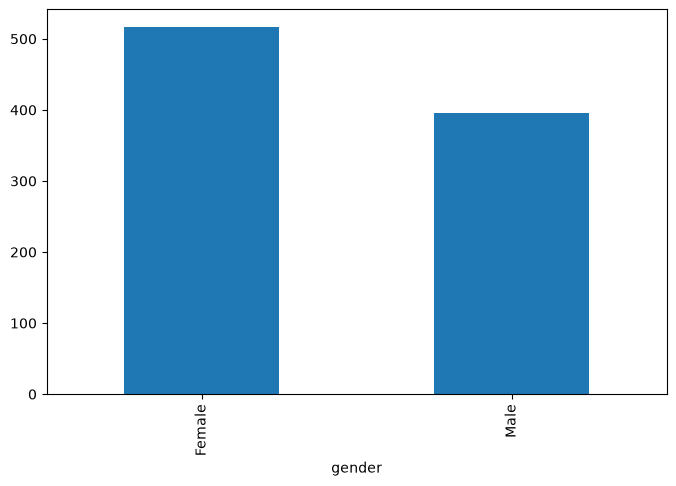

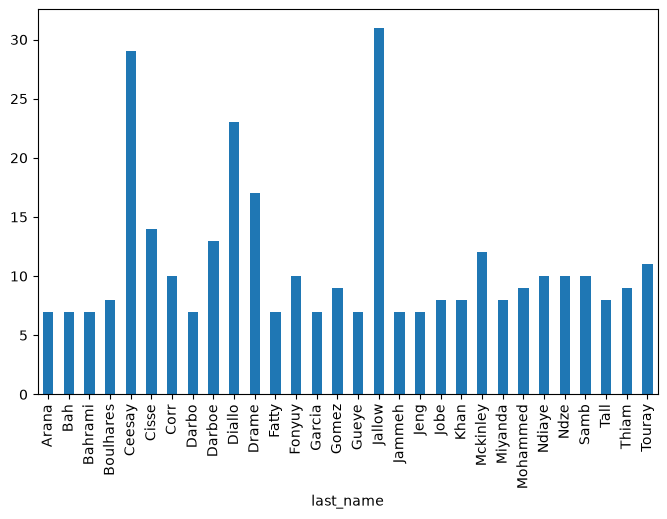

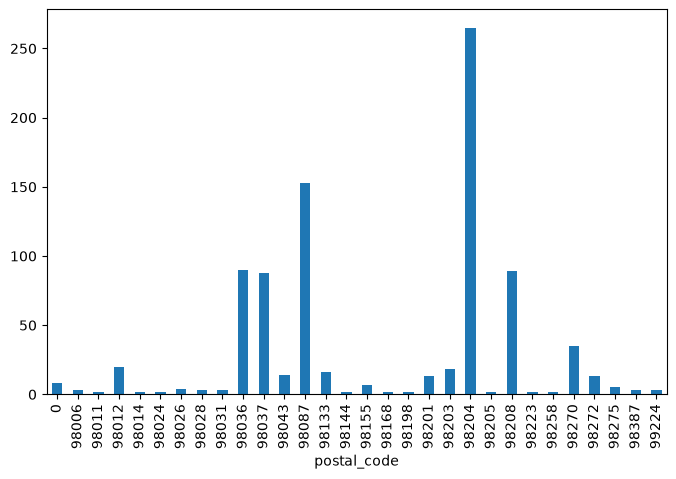

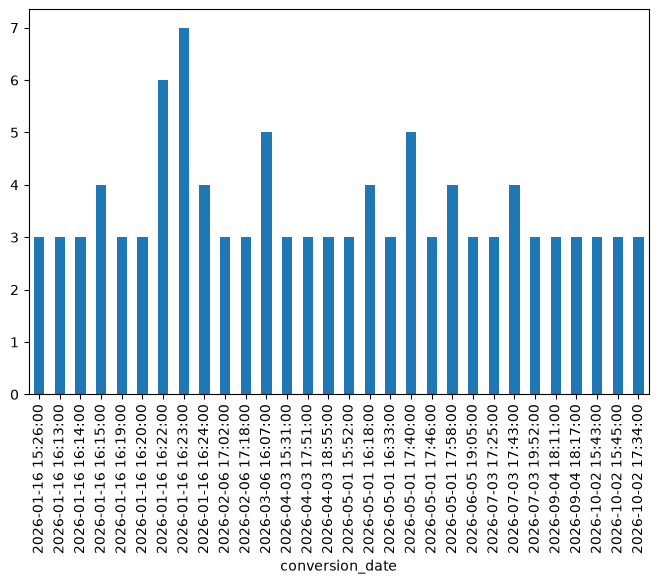

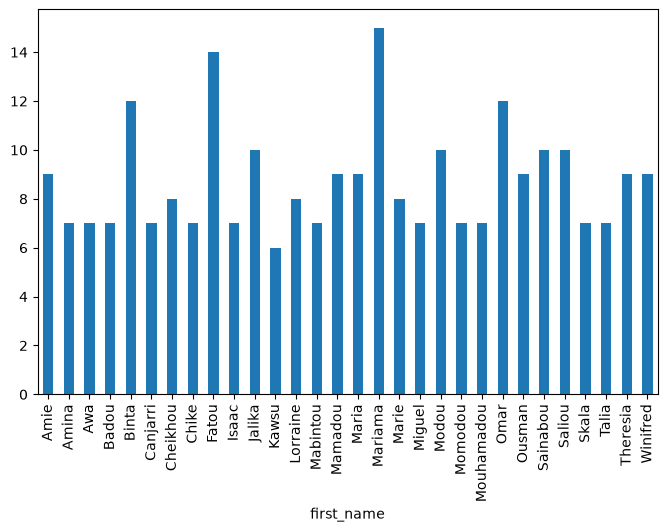

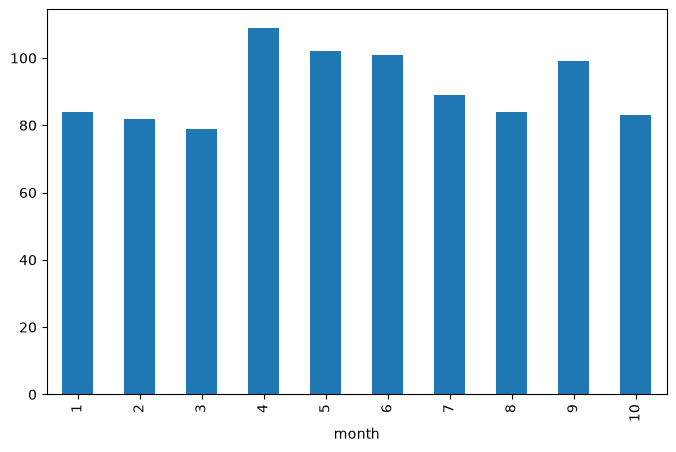

In [42]:
##### Distribution - qual_vars
for col in qual_vars:
    qual_nums = df[col].value_counts()[:30]
    qual_nums = qual_nums.sort_index()
    # print(qual_nums)
    ax = qual_nums.plot.bar(
        figsize=(8,5)
    )

    plt.show()